In [1]:
import os
import pandas as pd
import numpy as np
from functools import reduce
import matplotlib.pyplot as plt

In [33]:
files_to_compare = [
    r"C:\Users\jvill\Downloads\KPMP_QC_images\Normalized_BackgroundRemoved_HSI_sam_outputs\C-DM-ROI1-HSI-500mW-step.5slice5-scale70-HV500-20us-zoom2\C-DM-ROI1-HSI-500mW-step.5slice5-scale70-HV500-20us-zoom2_sam_predictions.csv",
    r"C:\Users\jvill\Downloads\KPMP_QC_images\Normalized_BackgroundRemoved_HSI_sam_outputs\C-DM-ROI1-HSI-500mW-step.5slice5-scale70-HV500-20us-zoom2-QC\C-DM-ROI1-HSI-500mW-step.5slice5-scale70-HV500-20us-zoom2-QC_sam_predictions.csv"
]
n_contenders = 3
cols_to_compare = [
    f"Contender_{n}" for n in range(1,n_contenders+1)
]
cols_to_compare.append('Best_Match')

In [ ]:
df_list=[]
if os.path.splitext(files_to_compare[0])[-1] == ".csv":
    for file in files_to_compare:
        df = pd.read_csv(file)
        df_list.append(df)
elif os.path.splitext(files_to_compare[0])[-1] == ".parquet":
    for file in files_to_compare:
        df = pd.read_parquet(file)
        df_list.append(df)
else:
    raise Exception("File format not supported.")
df_mask = df_list[1]['Best_Similarity'] != 0.5 # Mask for non valid (zero) pixels due to transformation

In [35]:
set_consensus_ratio = []
for rows in zip(*[df[cols_to_compare].values for df[df_mask]in df_list]):
    # Find the intersection of sets across all rows
    intersection = reduce(set.intersection, map(set, rows))
    # Divide by total columns to get the ratio
    set_consensus_ratio.append(len(intersection) / len(cols_to_compare))

In [36]:
comparison_rows = zip(*[df[cols_to_compare].values for df[df_mask] in df_list[1:]])
pool_sets_per_row = [set().union(*map(set, row_group)) for row_group in comparison_rows]

# Check if any element in df1's row intersects with the comparison pool for that row
has_set_overlap = []
for idx, df1_row in enumerate(df_list[0][cols_to_compare].values):
    # Check if df1 row categories have an intersection with the pool set
    overlap_detected = not set(df1_row).isdisjoint(pool_sets_per_row[idx])
    has_set_overlap.append(overlap_detected)

In [37]:
dm_metrics_pix_overlap_ratio = np.median(set_consensus_ratio).astype(np.float16)
dm_metrics_overlap_ratio = np.median(has_set_overlap).astype(np.float16)
dm_n_pixels = len(df_list[0][df_mask])

In [7]:
ref1_metrics_pix_overlap_ratio = np.median(set_consensus_ratio).astype(np.float16)
ref1_metrics_overlap_ratio = np.median(has_set_overlap).astype(np.float16)
ref1_n_pixels = len(df_list[0][df_mask])

In [6]:
ref2_metrics_pix_overlap_ratio = np.median(set_consensus_ratio).astype(np.float16)
ref2_metrics_overlap_ratio = np.median(has_set_overlap).astype(np.float16)
ref2_n_pixels = len(df_list[0][df_mask])

In [23]:
ref_metrics_pix_overlap_ratio = np.median(set_consensus_ratio).astype(np.float16)
ref_metrics_overlap_ratio = np.median(has_set_overlap).astype(np.float16)
ref_n_pixels = len(df_list[0][df_mask])

In [38]:
dm_n_pixels/len(df_list[0]), dm_metrics_overlap_ratio, dm_metrics_pix_overlap_ratio


(0.9999990463256836, np.float16(1.0), np.float16(1.0))

In [28]:
4408*1973

8696984

In [14]:
len(df_list[0])

8696984

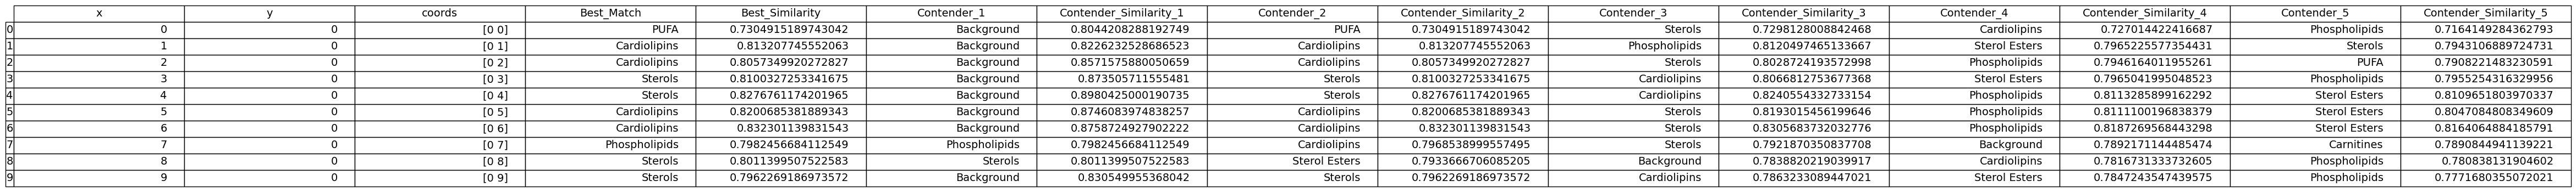

In [ ]:
df = df_list[0]
# Get the head
df_head = df.head(10)

# Create a matplotlib figure
fig, ax = plt.subplots(figsize=(6, 2)) 
ax.axis('off')

# Create the table and add it to the plot
table = ax.table(
    cellText=df_head.values, 
    colLabels=df_head.columns, 
    rowLabels=df_head.index,
    loc='center'
)
# 1. Override the automatic font size rules
table.auto_set_font_size(False)

# 2. Set your custom font size (e.g., 14)
table.set_fontsize(14)

# 3. Scale the row heights and widths so the larger text fits perfectly
table.scale(10, 1.8) 

plt.show()

In [6]:
df_mask = df_list[1]['Best_Similarity'] != 0.5

In [47]:
df_list[0]['Best_Similarity']

0          0.816590
1          0.898557
2          0.887072
3          0.901208
4          0.907081
             ...   
8447635    0.920531
8447636    0.921848
8447637    0.909535
8447638    0.916546
8447639    0.903148
Name: Best_Similarity, Length: 8447640, dtype: float32

In [48]:
df_list[0][df_mask]

,x,y,coords,Best_Match,Best_Similarity,Contender_1,Contender_Similarity_1,Contender_2,Contender_Similarity_2,Contender_3,Contender_Similarity_3,Contender_4,Contender_Similarity_4,Contender_5,Contender_Similarity_5
0,0,0,"[0, 0]",Sterols,0.816590,Background,0.834850,Sterols,0.816590,Sterol Esters,0.799043,Cardiolipins,0.796895,Phospholipids,0.793752
1,1,0,"[0, 1]",Sterols,0.898557,Sterols,0.898557,Sterol Esters,0.892253,Background,0.890290,Cardiolipins,0.888917,Phospholipids,0.887754
2,2,0,"[0, 2]",Cardiolipins,0.887072,Background,0.898054,Cardiolipins,0.887072,Sterols,0.883256,Phospholipids,0.881674,Sterol Esters,0.878386
3,3,0,"[0, 3]",Cardiolipins,0.901208,Cardiolipins,0.901208,Background,0.898966,Phospholipids,0.895255,Sterols,0.886793,Sterol Esters,0.882598
4,4,0,"[0, 4]",Lysophospholipids,0.907081,Lysophospholipids,0.907081,Phospholipids,0.905314,Sterol Esters,0.890716,Cardiolipins,0.890001,Sterols,0.877486
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8255576,2276,3355,"[3355, 2276]",Sterols,0.890857,Background,0.908470,Sterols,0.890857,Sterol Esters,0.881116,Cardiolipins,0.880553,Phospholipids,0.876159
8255577,2277,3355,"[3355, 2277]",Sterols,0.889946,Background,0.907304,Sterols,0.889946,Cardiolipins,0.881126,Phospholipids,0.879886,Sterol Esters,0.879172
8255578,2278,3355,"[3355, 2278]",Sterols,0.901159,Sterols,0.901159,Background,0.898033,Sterol Esters,0.891921,Phospholipids,0.891398,Cardiolipins,0.888511
8255579,2279,3355,"[3355, 2279]",Sterols,0.910086,Sterols,0.910086,Phospholipids,0.907755,Sterol Esters,0.906162,Lysophospholipids,0.900755,Cardiolipins,0.899715


In [49]:
df_list[1][df_mask]

,x,y,coords,Best_Match,Best_Similarity,Contender_1,Contender_Similarity_1,Contender_2,Contender_Similarity_2,Contender_3,Contender_Similarity_3,Contender_4,Contender_Similarity_4,Contender_5,Contender_Similarity_5
0,0,0,"[0, 0]",Sterols,0.819518,Background,0.856342,Sterols,0.819518,Cardiolipins,0.802685,Sterol Esters,0.801035,Phospholipids,0.790639
1,1,0,"[0, 1]",Sterols,0.812501,Background,0.850969,Sterols,0.812501,Cardiolipins,0.801058,Sterol Esters,0.795292,PUFA,0.792095
2,2,0,"[0, 2]",Sterols,0.781124,Background,0.814039,Sterols,0.781124,Cardiolipins,0.772575,Sterol Esters,0.769762,Phospholipids,0.758750
3,3,0,"[0, 3]",Sterols,0.783046,Background,0.817609,Sterols,0.783046,Sterol Esters,0.773225,Cardiolipins,0.769867,Phospholipids,0.760878
4,4,0,"[0, 4]",Sterols,0.827432,Background,0.862652,Sterols,0.827432,Cardiolipins,0.818721,Sterol Esters,0.818561,Phospholipids,0.811434
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8255576,2276,3355,"[3355, 2276]",Sterols,0.796529,Background,0.841664,Sterols,0.796529,Cardiolipins,0.789993,PUFA,0.789934,Phospholipids,0.777162
8255577,2277,3355,"[3355, 2277]",Sterols,0.815709,Background,0.841907,Sterols,0.815709,Cardiolipins,0.811276,Phospholipids,0.802789,Sterol Esters,0.802703
8255578,2278,3355,"[3355, 2278]",Cardiolipins,0.804564,Background,0.852218,Cardiolipins,0.804564,Sterols,0.803101,Phospholipids,0.794279,Sterol Esters,0.790400
8255579,2279,3355,"[3355, 2279]",Sterols,0.806881,Background,0.853818,Sterols,0.806881,Cardiolipins,0.805877,Sterol Esters,0.794203,Phospholipids,0.793711


In [50]:
df_list[1]

,x,y,coords,Best_Match,Best_Similarity,Contender_1,Contender_Similarity_1,Contender_2,Contender_Similarity_2,Contender_3,Contender_Similarity_3,Contender_4,Contender_Similarity_4,Contender_5,Contender_Similarity_5
0,0,0,"[0, 0]",Sterols,0.819518,Background,0.856342,Sterols,0.819518,Cardiolipins,0.802685,Sterol Esters,0.801035,Phospholipids,0.790639
1,1,0,"[0, 1]",Sterols,0.812501,Background,0.850969,Sterols,0.812501,Cardiolipins,0.801058,Sterol Esters,0.795292,PUFA,0.792095
2,2,0,"[0, 2]",Sterols,0.781124,Background,0.814039,Sterols,0.781124,Cardiolipins,0.772575,Sterol Esters,0.769762,Phospholipids,0.758750
3,3,0,"[0, 3]",Sterols,0.783046,Background,0.817609,Sterols,0.783046,Sterol Esters,0.773225,Cardiolipins,0.769867,Phospholipids,0.760878
4,4,0,"[0, 4]",Sterols,0.827432,Background,0.862652,Sterols,0.827432,Cardiolipins,0.818721,Sterol Esters,0.818561,Phospholipids,0.811434
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8447635,2455,3433,"[3433, 2455]",No Match,0.500000,Sterols,0.500000,Sterol Esters,0.500000,Cardiolipins,0.500000,Phospholipids,0.500000,Lysophospholipids,0.500000
8447636,2456,3433,"[3433, 2456]",No Match,0.500000,Sterols,0.500000,Sterol Esters,0.500000,Cardiolipins,0.500000,Phospholipids,0.500000,Lysophospholipids,0.500000
8447637,2457,3433,"[3433, 2457]",No Match,0.500000,Sterols,0.500000,Sterol Esters,0.500000,Cardiolipins,0.500000,Phospholipids,0.500000,Lysophospholipids,0.500000
8447638,2458,3433,"[3433, 2458]",No Match,0.500000,Sterols,0.500000,Sterol Esters,0.500000,Cardiolipins,0.500000,Phospholipids,0.500000,Lysophospholipids,0.500000


In [51]:
df_list[0]

,x,y,coords,Best_Match,Best_Similarity,Contender_1,Contender_Similarity_1,Contender_2,Contender_Similarity_2,Contender_3,Contender_Similarity_3,Contender_4,Contender_Similarity_4,Contender_5,Contender_Similarity_5
0,0,0,"[0, 0]",Sterols,0.816590,Background,0.834850,Sterols,0.816590,Sterol Esters,0.799043,Cardiolipins,0.796895,Phospholipids,0.793752
1,1,0,"[0, 1]",Sterols,0.898557,Sterols,0.898557,Sterol Esters,0.892253,Background,0.890290,Cardiolipins,0.888917,Phospholipids,0.887754
2,2,0,"[0, 2]",Cardiolipins,0.887072,Background,0.898054,Cardiolipins,0.887072,Sterols,0.883256,Phospholipids,0.881674,Sterol Esters,0.878386
3,3,0,"[0, 3]",Cardiolipins,0.901208,Cardiolipins,0.901208,Background,0.898966,Phospholipids,0.895255,Sterols,0.886793,Sterol Esters,0.882598
4,4,0,"[0, 4]",Lysophospholipids,0.907081,Lysophospholipids,0.907081,Phospholipids,0.905314,Sterol Esters,0.890716,Cardiolipins,0.890001,Sterols,0.877486
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8447635,2455,3433,"[3433, 2455]",Phospholipids,0.920531,Phospholipids,0.920531,Sterol Esters,0.917709,Lysophospholipids,0.917170,Cardiolipins,0.910607,Sterols,0.908140
8447636,2456,3433,"[3433, 2456]",Cardiolipins,0.921848,Cardiolipins,0.921848,Phospholipids,0.920060,Sterol Esters,0.919376,Sterols,0.919203,Background,0.906872
8447637,2457,3433,"[3433, 2457]",Sterols,0.909535,Sterols,0.909535,Sterol Esters,0.907678,Cardiolipins,0.907433,Phospholipids,0.905600,Background,0.898736
8447638,2458,3433,"[3433, 2458]",Sterols,0.916546,Sterols,0.916546,Cardiolipins,0.913301,Background,0.912720,Sterol Esters,0.909206,Phospholipids,0.906988
